# Melbourne's footpaths through a day

The City of Melbourne counts people walking past more than 100 sensors, every hour. A count is a number at a point.
How crowded a footpath feels depends on how wide it is, and the counts don't say. The council publishes its footpaths
as outlines too, but not which footpath each sensor counts.

The shapes in `data/geometry/` were made in [Plotlay](https://www.getplotlay.com). For each of the 53 sensors with a
clear footpath, the council's own footpath outline was picked with one click. The Princes Bridge zone is a strip along
the bridge at the council polygon's width. The sensors were then joined to the zones by position, and each zone was
keyed by its sensor's id. With a shape there is an area and an edge, so there is a width. With a width, a count becomes
people per metre of footpath and space per person.

This notebook reads only the files in `../data`, recomputes every number it shows, and runs top to bottom in under a
minute.

In [1]:
import json, math
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

DATA = '../data'
pd.set_option('display.width', 140)
INK, RED, MUTED, FILM = '#1d4f91', '#cf3b26', '#5b6573', '#f2efe6'
WALK = 1.2          # m/s: the walking speed assumed for space per person
CAR = 2.4 * 5.4     # a car space (AS/NZS 2890.1, user class 1A): 12.96 m²
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

## Sources and licence

Pedestrian counts, sensor locations and footpaths: City of Melbourne Open Data, under CC BY 4.0. The counts cover 1
November 2025 to 31 October 2026. The footpath zones were made in Plotlay from the council's footpath outlines, and one
was drawn as a strip. There is nothing from OpenStreetMap and no imagery in this repository. The full credits are in
`NOTICE`.

## Load the tables

- `sensors.csv`: the 57 sensors with at least 300 complete days in the 12 months. Each has its zone check, and four have
  no zone, with the reason given.
- `hour_of_day.csv`: the average people in each hour of the day, weekdays and weekends apart, as the council's portal
  worked them out (`avg(pedestriancount)` grouped by sensor and hour).
- `daily_totals.csv`: people a day per sensor, with the hours reported (24 is a complete day).

In [2]:
sensors = pd.read_csv(f'{DATA}/counts/sensors.csv')
hours = pd.read_csv(f'{DATA}/counts/hour_of_day.csv')
daily = pd.read_csv(f'{DATA}/counts/daily_totals.csv', parse_dates=['date'])
zones = gpd.read_file(f'{DATA}/geometry/footpath_zones.geojson')
zones['sensor_key'] = zones['key'].astype(int)
assert sensors.sensor_key.is_unique and zones.sensor_key.is_unique
assert not hours.duplicated(['sensor_key', 'hour']).any()
print(len(sensors), 'sensors,', len(zones), 'zones,', hours.sensor_key.nunique(), 'with hours,', len(daily), 'sensor-days')
sensors.zone_check.value_counts()

57 sensors, 53 zones, 53 with hours, 20728 sensor-days


zone_check
ok              49
no zone          4
adjusted         2
can’t verify     2
Name: count, dtype: int64

## Width from the shape

A footpath zone is a long, thin outline. For a strip of length L and width W, the area is A = L × W and the edge is
P = 2(L + W). Solving those gives W = (P − √(P² − 16A)) / 4. Plotlay worked this out as the formula column `width_m`.
Here it is again from the exported area and perimeter, and checked against a second method: the area divided by the
long side of the smallest box around the shape. Zones whose two widths differ by more than 20% are left out of the
comparisons.

In [3]:
m = zones.to_crs(7855)        # GDA2020 MGA zone 55, metres
def w_box(g):
    r = list(g.minimum_rotated_rectangle.exterior.coords)
    return g.area / max(math.dist(r[0], r[1]), math.dist(r[1], r[2]))
zones['width_formula'] = (zones.perimeter_m - np.sqrt(zones.perimeter_m ** 2 - 16 * zones.area_m2)) / 4
zones['width_box'] = m.geometry.apply(w_box)
zones['area_mga'] = m.area
print('largest difference, Plotlay area vs GDA2020 MGA 55:', round(float(((zones.area_m2 / zones.area_mga) - 1).abs().max() * 100), 2), '%')
print('width formula vs Plotlay width_m:', round(float((zones.width_formula - zones.width_m).abs().max()), 3), 'm')
s = sensors.merge(zones[['sensor_key', 'width_box']], on='sensor_key', how='left')
s['width_ok'] = ((s.width_m / s.width_box) - 1).abs() <= 0.2
comp = s[s['compare'] & s.width_ok]
print(len(comp), 'zones compared')

largest difference, Plotlay area vs GDA2020 MGA 55: 0.13 %
width formula vs Plotlay width_m: 0.005 m
51 zones compared


## The city through a day

Add the 53 sensors' hourly averages together and the city breathes in and out.

weekday: 1,051 an hour at 4:00, 67,022 at 17:00, 64 times as many
midnight: weekends 3.1 times weekdays


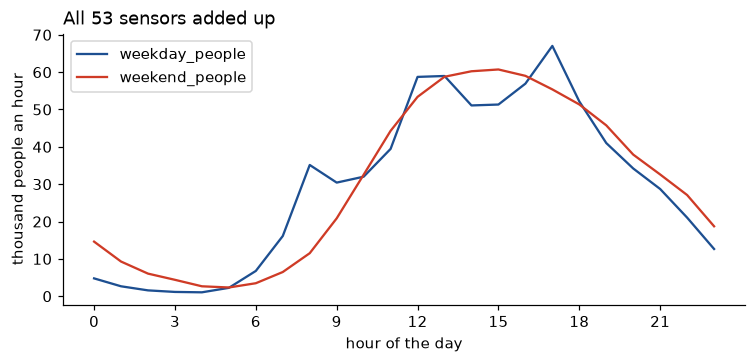

In [4]:
city = hours.groupby('hour')[['weekday_people', 'weekend_people']].sum()
lo, hi = city.weekday_people.idxmin(), city.weekday_people.idxmax()
print(f'weekday: {city.weekday_people.min():,.0f} an hour at {lo}:00, {city.weekday_people.max():,.0f} at {hi}:00, '
      f'{city.weekday_people.max() / city.weekday_people.min():.0f} times as many')
print(f'midnight: weekends {city.weekend_people[0] / city.weekday_people[0]:.1f} times weekdays')
ax = (city / 1000).plot(color=[INK, RED], figsize=(8, 3.2))
ax.set_ylabel('thousand people an hour'); ax.set_xlabel('hour of the day'); ax.set_xticks(range(0, 24, 3))
ax.set_title(f'All {hours.sensor_key.nunique()} sensors added up', loc='left');

## Space per person at the busiest hour

People an hour on each metre of width is the flow. If everyone walks at a steady 1.2 m/s, the number of people on
each square metre is flow ÷ speed, so the space each person has is speed × 3600 × width ÷ people an hour. This is an
estimate. It averages over the hour, so the busiest minutes are busier. It also counts the whole footpath width,
including street furniture and café tables. At 1.0 m/s everyone would have 17% less space.

In [5]:
peak = hours.groupby('sensor_key').agg(peak_wd=('weekday_people', 'max'), peak_we=('weekend_people', 'max'))
peak['hour_wd'] = hours.loc[hours.groupby('sensor_key').weekday_people.idxmax()].set_index('sensor_key').hour
p = comp.set_index('sensor_key').join(peak)
p['m2_weekday'] = WALK * 3600 * p.width_m / p.peak_wd
p['m2_weekend'] = WALK * 3600 * p.width_m / p.peak_we
cols = ['sensor_name', 'width_m', 'peak_wd', 'hour_wd', 'm2_weekday', 'm2_weekend']
p.sort_values('m2_weekday')[cols].head(8).round(1)

,sensor_name,width_m,peak_wd,hour_wd,m2_weekday,m2_weekend
sensor_key,,,,,,
9,Southern Cross Station,4.4,2598.4,8,7.3,91.7
24,Spencer St-Collins St (North),5.3,2822.3,17,8.1,17.9
184,124 Elizabeth Street,4.5,2405.3,13,8.1,8.4
58,Bourke St - Spencer St (North),3.5,1750.4,17,8.6,13.8
84,Elizabeth St - Flinders St (East) - New footpath,5.8,2841.0,17,8.8,11.0
135,I-Hub Southern Cross Station - Bourke Street E...,2.2,1043.6,17,9.1,9.9
133,I-Hub Southern Cross Station - Lonsdale Street...,2.7,1274.6,17,9.2,9.8
5,Princes Bridge,5.0,2310.9,17,9.3,7.9


In [6]:
sc, th = p.loc[9], p.loc[4]
print(f"Southern Cross Station: {sc.peak_wd:,.0f} people an hour at {sc.hour_wd:.0f}:00 on {sc.width_m:.1f} m: "
      f"{sc.m2_weekday:.1f} m² each ({sc.m2_weekday / CAR:.2f} of a car space); at the weekend's busiest hour {sc.m2_weekend:.0f} m²")
print(f"Town Hall (West): {th.peak_wd:,.0f} an hour on {th.width_m:.1f} m: {th.m2_weekday:.1f} m² each on weekdays, {th.m2_weekend:.1f} at weekends")
print(f"median of the {len(p)} compared footpaths: {p.m2_weekday.median():.1f} m² each on weekdays, {p.m2_weekend.median():.1f} at weekends")

Southern Cross Station: 2,598 people an hour at 8:00 on 4.4 m: 7.3 m² each (0.56 of a car space); at the weekend's busiest hour 92 m²
Town Hall (West): 3,366 an hour on 8.1 m: 10.4 m² each on weekdays, 9.2 at weekends
median of the 51 compared footpaths: 16.2 m² each on weekdays, 18.1 at weekends


## Weekday city, weekend city

Plotlay's formula column `weekend_vs_weekday` divides the average weekend day by the average weekday (each the sum of
the 24 hourly averages). Here it is again, and also from complete days only.

In [7]:
r = (hours.groupby('sensor_key').weekend_people.sum() / hours.groupby('sensor_key').weekday_people.sum()).round(2)
full = daily[daily.hours_reported == 24].copy(); full['weekend'] = full.date.dt.day_of_week >= 5
rd = full.groupby(['sensor_key', 'weekend']).people.mean().unstack()
t = sensors.set_index('sensor_key')[['sensor_name']].join(r.rename('from_hours')).join((rd[True] / rd[False]).round(2).rename('from_complete_days'))
t = t.dropna().sort_values('from_hours')
pd.concat([t.head(4), t.tail(4)])

,sensor_name,from_hours,from_complete_days
sensor_key,,,
9,Southern Cross Station,0.16,0.16
17,Collins Place (South),0.38,0.38
109,La Trobe St- William St (South),0.53,0.53
23,Spencer St-Collins St (South),0.54,0.54
29,St Kilda Rd-Alexandra Gardens,1.44,1.43
27,QV Market-Peel St,1.49,1.48
20,Chinatown-Lt Bourke St (South),1.56,1.54
31,Lygon St (West),1.58,1.57


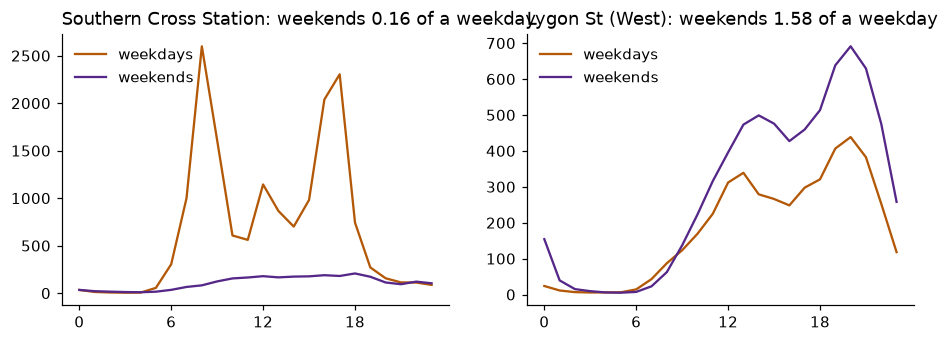

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (k, name) in zip(axs, [(9, 'Southern Cross Station'), (31, 'Lygon St (West)')]):
    x = hours[hours.sensor_key == k].set_index('hour')
    ax.plot(x.weekday_people, color='#b35806', label='weekdays'); ax.plot(x.weekend_people, color='#542788', label='weekends')
    ax.set_title(f'{name}: weekends {r[k]} of a weekday', loc='left'); ax.set_xticks(range(0, 24, 6)); ax.legend(frameon=False)

## The busiest days

The zoned sensors are added up on the days when all but two of them reported all 24 hours.

In [9]:
zk = set(zones.sensor_key)
fz = full[full.sensor_key.isin(zk)]
n = fz.groupby('date').sensor_key.nunique(); ok = n[n >= len(zk) - 2].index
cd = fz[fz.date.isin(ok)].groupby('date').people.sum().sort_values(ascending=False)
sat = cd[cd.index.day_of_week == 5]
print(len(ok), 'days counted; median Saturday', f'{sat.median():,.0f}')
cd.head(5).to_frame('people').assign(weekday=lambda d: d.index.day_name())

225 days counted; median Saturday 810,796


,people,weekday
date,,
2026-03-07,1003937,Saturday
2026-03-08,997002,Sunday
2026-03-06,965643,Friday
2026-04-04,943470,Saturday
2026-03-05,920328,Thursday


## A map

Each footpath zone is coloured by the space each person has at its busiest weekday hour, darkest where it is tightest.

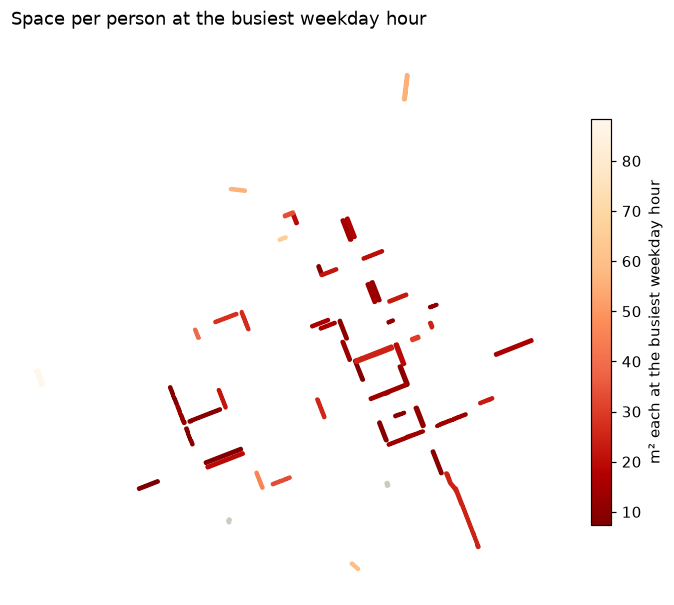

In [10]:
z = m.merge(p[['m2_weekday']], left_on='sensor_key', right_index=True, how='left')
ax = z.plot(column='m2_weekday', cmap='OrRd_r', scheme=None, figsize=(8, 8), legend=True, missing_kwds={'color': '#cfcac0'},
            linewidth=2.5, edgecolor='face', legend_kwds={'label': 'm² each at the busiest weekday hour', 'shrink': .6})
ax.set_axis_off(); ax.set_title('Space per person at the busiest weekday hour', loc='left');

## Notes

- Zones were checked against the council footpaths, building footprints and road corridors at full size. The note on
  each sensor in `sensors.csv` says why a zone was adjusted, why it can't be verified, or why there is none.
- Sensors on building walls sit up to 10.8 m from the footpath they count. In Plotlay they were joined to the nearest
  zone within 12 m. Every one of them is more than 100 m from any other zone.
- Counts are as the council publishes them. Missing hours are left out of the averages, never filled in.